# CODE 2.1: Explore the Data (EDA)

> **Goal:** get to know the chewing gum photos before we train any model. We answer seven questions:
>
> 1. How many photos are there?
> 2. Which defect types are there?
> 3. What do the defects look like?
> 4. What is a mask?
> 5. How big are the defects?
> 6. Where in the photo are the defects?
> 7. Is every defect one clean piece in its mask?
>
> - **Input:** the original data in `data/raw/chewinggum/` and `splits/same_gum_photos.csv` (notebook 1.2)
> - **Output:** no files. Only tables and figures.
>
> We look at all photos here to describe the data. No model learns anything in this notebook, and no setting is chosen from the test photos.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`: works with numbers and pixels.
> - `pandas`: works with tables.
> - `matplotlib`: draws the figures.
> - `PIL` (Pillow): opens photos and masks.
> - `scipy.ndimage`: finds the separate pieces of a defect in a mask (question 7).
> - `tqdm`: shows a progress bar while the code goes through many photos.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator
from PIL import Image
from scipy import ndimage
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `ROOT_DIR`: the main project folder.
> - `RAW_DIR`: the original data. We only read from it.
> - `GUM_DIR`: the chewing gum photos, masks and photo list.
> - `SAME_GUM_FILE`: the list of photos that show the same gum (notebook 1.2).
>
> If a file is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

RAW_DIR = os.path.join(ROOT_DIR, "data", "raw")
GUM_DIR = os.path.join(RAW_DIR, "chewinggum")
SAME_GUM_FILE = os.path.join(ROOT_DIR, "splits", "same_gum_photos.csv")

if not os.path.exists(os.path.join(GUM_DIR, "image_anno.csv")):
    raise FileNotFoundError("Data not found. Copy the 'chewinggum' folder into data/raw/ (see README).")
if not os.path.exists(SAME_GUM_FILE):
    raise FileNotFoundError("splits/same_gum_photos.csv not found. Run notebook 1.2 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Defect Types and Display Settings

> - `DEFECT_TYPES`: the 5 defect types used in the data, each with a short description of what it looks like (see question 3).
> - `MASK_CODE`: which defect type each number in a mask means, from VisA's `utils/id2class.py`. Notebook 1.1 checks it, and shows that number 6 (*other*) is never used.
> - `TYPE_CODE`: the same as `MASK_CODE`, the other way round.
> - `SHOW_WIDTH`: photos are made smaller to this width (in pixels) before showing, so the notebook stays light.
> - `MAP_SIZE`: the size of the small maps in question 6, about a quarter of the photo size.
> - `TOUCHING`: which pixels count as touching in question 7: the 8 pixels around a pixel, so also corner to corner.

In [3]:
DEFECT_TYPES = {
    "chunk of gum missing": "a piece of the top surface is gone (a rough hole)",
    "corner missing": "a piece is broken off an edge or corner",
    "small cracks": "thin cracks in the surface",
    "similar colour spot": "a faint stain, close to the gum's own colour",
    "scratches": "thin scratch lines on the surface",
}
MASK_CODE = {1: "chunk of gum missing", 2: "corner missing", 3: "scratches",
             4: "similar colour spot", 5: "small cracks"}
TYPE_CODE = {name: number for number, name in MASK_CODE.items()}

SHOW_WIDTH = 560
MAP_SIZE = (336, 280)
TOUCHING = np.ones((3, 3), dtype=bool)

## Functions

### Open a Mask

> `open_mask()` opens a mask as a table of numbers (0 = no defect, 1 to 5 = defect type).

In [4]:
def open_mask(rel_path):
    return np.asarray(Image.open(os.path.join(RAW_DIR, rel_path)))

### Box Around a Defect

> `defect_box()` finds the smallest box (left, top, right, bottom) that holds all defect pixels.

In [5]:
def defect_box(defect_pixels):
    rows, cols = np.nonzero(defect_pixels)
    return cols.min(), rows.min(), cols.max() + 1, rows.max() + 1

### Square for a Close-up

> `square_around()` makes a square box around a defect box, for close-ups. `margin` adds space on every side, `min_side` is the smallest size of the square. The square is moved, if needed, so it stays inside the photo.

In [6]:
def square_around(box, photo_width, photo_height, margin, min_side):
    left, top, right, bottom = box
    side = max(right - left, bottom - top) + 2 * margin
    side = min(max(side, min_side), photo_width, photo_height)
    center_x, center_y = (left + right) // 2, (top + bottom) // 2
    new_left = min(max(center_x - side // 2, 0), photo_width - side)
    new_top = min(max(center_y - side // 2, 0), photo_height - side)
    return new_left, new_top, new_left + side, new_top + side

### Photo with a Close-up

> `show_with_close_up()` shows a photo (made smaller to `show_width`) with a yellow box in the `top` panel, and a close-up of that box in the `bottom` panel.

In [7]:
def show_with_close_up(top, bottom, rel_path, box, title, show_width):
    img = Image.open(os.path.join(RAW_DIR, rel_path)).convert("RGB")
    scale = show_width / img.width
    top.imshow(img.resize((show_width, round(img.height * scale))))
    left, upper, right, lower = box
    top.add_patch(Rectangle((left * scale, upper * scale), (right - left) * scale, (lower - upper) * scale,
                            fill=False, edgecolor="yellow", linewidth=2))
    bottom.imshow(img.crop(box))
    top.set_title(title)
    top.axis("off")
    bottom.axis("off")

## Load Data

### Load the Photo List and Measure the Defects

> We read the photo list. Then we open every mask and measure how much of the photo each defect type covers:
>
> *size (%) = defect pixels ÷ all pixels in the photo × 100*
>
> - `defects`: one row per defect photo, with the size of all its defects together.
> - `type_sizes`: one row per defect type in a photo, with its number of pixels and its size. A photo with two types gets two rows.

In [8]:
photos = pd.read_csv(os.path.join(GUM_DIR, "image_anno.csv")).fillna("")
photos["is_defect"] = photos["label"] != "normal"
defects = photos[photos["is_defect"]].copy()

rows = []
for i, photo in tqdm(defects.iterrows(), total=len(defects), desc="Measuring the defects in each mask"):
    mask = open_mask(photo["mask"])
    for number, name in MASK_CODE.items():
        n_pixels = int((mask == number).sum())
        if n_pixels > 0:
            rows.append({"photo": i, "defect type": name, "pixels": n_pixels,
                         "size %": 100 * n_pixels / mask.size})
type_sizes = pd.DataFrame(rows)
defects["size %"] = type_sizes.groupby("photo")["size %"].sum()

print(f"Pixels in one photo: {mask.shape[1]} x {mask.shape[0]} = {mask.size:,}")
print(f"{len(defects)} defect photos, {len(type_sizes)} defect types measured (a photo can have more than one)")

Measuring the defects in each mask:   0%|          | 0/100 [00:00<?, ?it/s]

Measuring the defects in each mask: 100%|██████████| 100/100 [00:01<00:00, 83.50it/s]

Pixels in one photo: 1342 x 1118 = 1,500,356
100 defect photos, 153 defect types measured (a photo can have more than one)


## Question 1: How Many Photos Are There?

### Count the Photos

> Normal photos against defect photos. We also print how many photos notebook 1.2 left out because they show the same gum as another photo. They stay in this notebook, because here we describe all the raw data, but they are not used for training or testing.

In [9]:
kinds = photos["is_defect"].map({False: "normal", True: "defect"}).rename("kind").value_counts()
print(kinds.to_string())
print(f"\nDefect photos are {kinds['defect'] / len(photos):.0%} of all photos.")

same_gum = pd.read_csv(SAME_GUM_FILE)
left_out = same_gum[~same_gum["keep"]]
print(f"Photos left out because they show the same gum as another photo: "
      f"{len(left_out)} ({(~left_out['is_defect']).sum()} normal, {left_out['is_defect'].sum()} defect)")
print(f"Normal photos used in the splits: {kinds['normal'] - (~left_out['is_defect']).sum()}")

kind
normal    503
defect    100

Defect photos are 17% of all photos.
Photos left out because they show the same gum as another photo: 6 (6 normal, 0 defect)
Normal photos used in the splits: 497


> **What we see:** only 17% of the photos show a defect. Good products are the large majority, like in a real factory. This is why collecting defect photos takes time. 6 normal photos are left out of the splits (notebook 1.2), so 497 normal photos are used later.

## Question 2: Which Defect Types Are There?

### Count the Defect Types

> A photo with two defect types is counted for both, so the photo counts add up to more than the number of defect photos.

In [10]:
types_per_photo = defects["label"].str.split(",")
type_table = (types_per_photo.explode().value_counts()
              .rename_axis("defect type").reset_index(name="photos"))
type_table["what it looks like"] = type_table["defect type"].map(DEFECT_TYPES)

n_multi = (types_per_photo.str.len() > 1).sum()
print(f"Photo counts added up: {type_table['photos'].sum()} (for {len(defects)} defect photos)")
print(f"Defect photos with more than one defect type: {n_multi} of {len(defects)}")
type_table

Photo counts added up: 153 (for 100 defect photos)
Defect photos with more than one defect type: 43 of 100


,defect type,photos,what it looks like
0,chunk of gum missing,47,a piece of the top surface is gone (a rough hole)
1,corner missing,36,a piece is broken off an edge or corner
2,small cracks,29,thin cracks in the surface
3,similar colour spot,25,"a faint stain, close to the gum's own colour"
4,scratches,16,thin scratch lines on the surface


> **What we see:** *chunk of gum missing* is the most common type (47 photos) and *scratches* the rarest (16 photos), so YOLO gets the fewest scratch examples to learn from. 43 of the 100 defect photos have more than one defect type, which is why the counts add up to 153.

## Question 3: What Do the Defects Look Like?

### Example Photos and Close-ups

> For each defect type we show the photo where this type is the biggest, so it is easy to see. Most defects are much smaller (question 5).
>
> - **Top row:** the whole photo. The yellow box shows where the defect is. We get the box from the mask (question 4).
> - **Bottom row:** a close-up of the yellow box.
> - **First column:** a normal photo with a close-up from the middle, to compare.

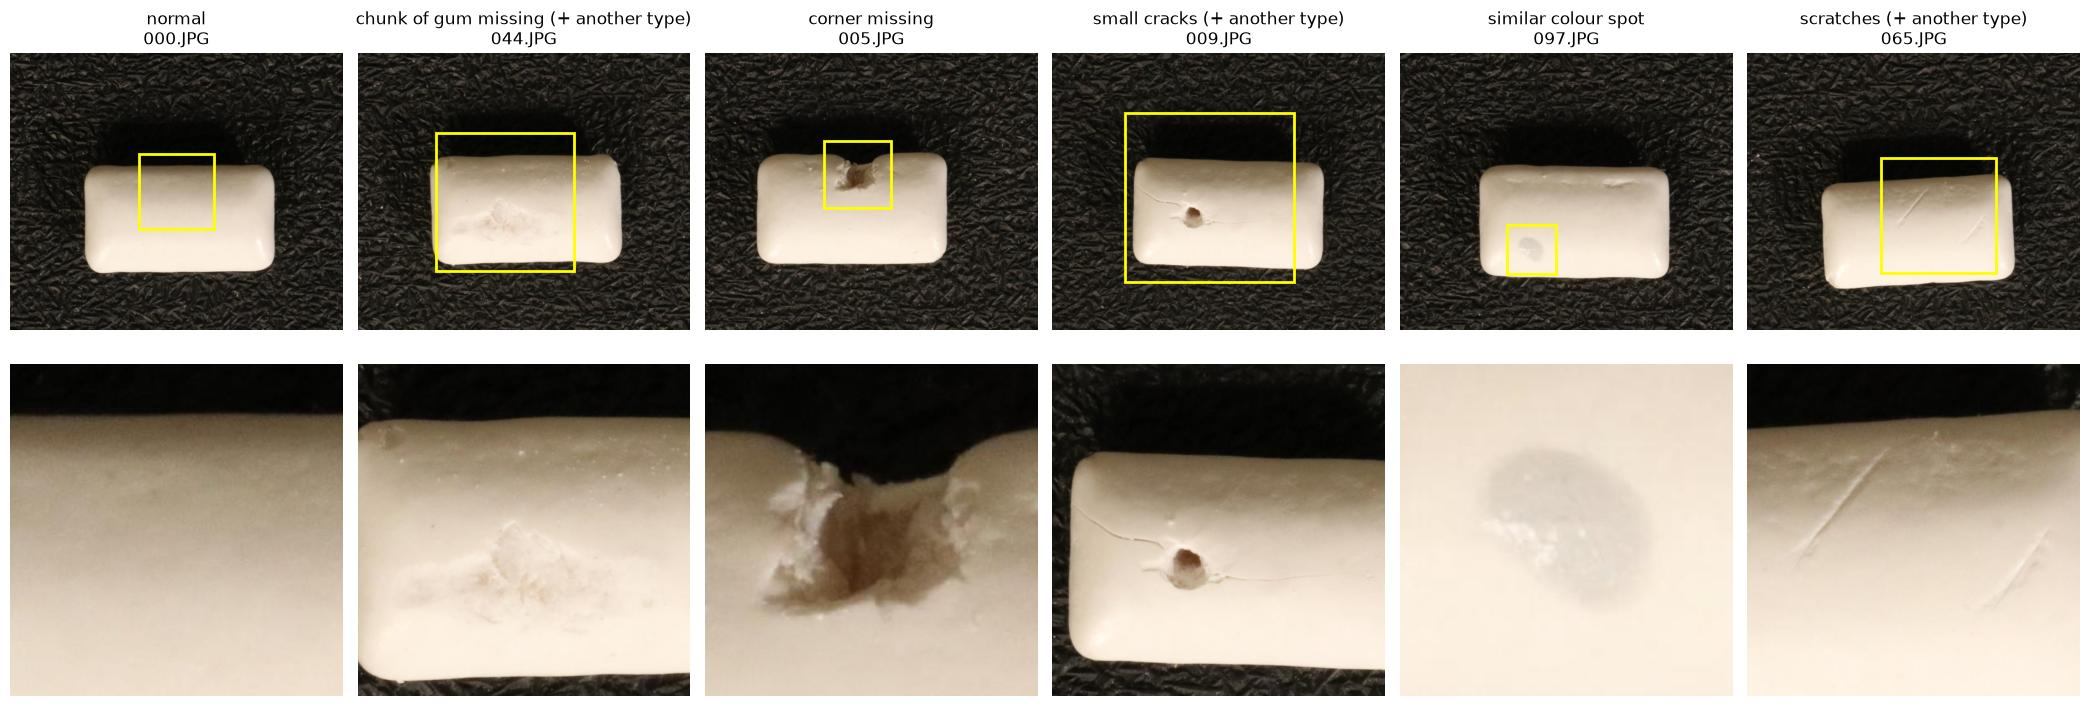

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(21, 7.5))

# a normal photo, with a close-up from the middle
normal = photos[~photos["is_defect"]].iloc[0]
width, height = Image.open(os.path.join(RAW_DIR, normal["image"])).size
middle = (width // 2, height // 2, width // 2, height // 2)
show_with_close_up(axes[0, 0], axes[1, 0], normal["image"],
                   square_around(middle, width, height, margin=40, min_side=300),
                   f"normal\n{os.path.basename(normal['image'])}", show_width=SHOW_WIDTH)

# for each defect type: the photo where this type is the biggest
for col, name in enumerate(DEFECT_TYPES, start=1):
    biggest = type_sizes[type_sizes["defect type"] == name].nlargest(1, "size %").iloc[0]
    photo = photos.loc[biggest["photo"]]
    this_type = open_mask(photo["mask"]) == TYPE_CODE[name]
    box = square_around(defect_box(this_type), this_type.shape[1], this_type.shape[0], margin=40, min_side=200)
    title = name if "," not in photo["label"] else name + " (+ another type)"
    show_with_close_up(axes[0, col], axes[1, col], photo["image"], box,
                       f"{title}\n{os.path.basename(photo['image'])}", show_width=SHOW_WIDTH)

plt.tight_layout()
plt.show()

> **What we see:**
>
> - The gum is a white bar on a dark, rough mat, always near the middle of the photo.
> - *chunk of gum missing* and *corner missing* are rough holes and broken edges. They are easy to see in the close-up.
> - *small cracks* and *scratches* are thin lines, and *similar colour spot* is a faint stain. They are much harder to see, even in these biggest examples.

## Question 4: What Is a Mask?

### Look Inside One Mask

> When you open a mask file, it looks completely black. The code below shows why:
>
> - A mask has the same size as its photo. Each pixel holds a number: `0` = no defect, `1` to `5` = the defect type.
> - The code prints the number type of the mask. This type can hold numbers from 0 (shown as black) to 255 (shown as white), so 1 to 5 look almost black.
> - If we multiply the numbers by 50, the defect becomes visible.
>
> Masks are **not** used to train PatchCore, because PatchCore learns from normal photos only. We use masks to:
>
> - make the boxes that YOLO learns from,
> - check if PatchCore's heatmap points at the right place,
> - show where the defect is in the demo.

Photo: 097.JPG | photo size: (1342, 1118) | mask size: (1342, 1118)
Numbers in this mask: [0 4]
Number type of the mask: uint8 (whole numbers from 0 to 255)


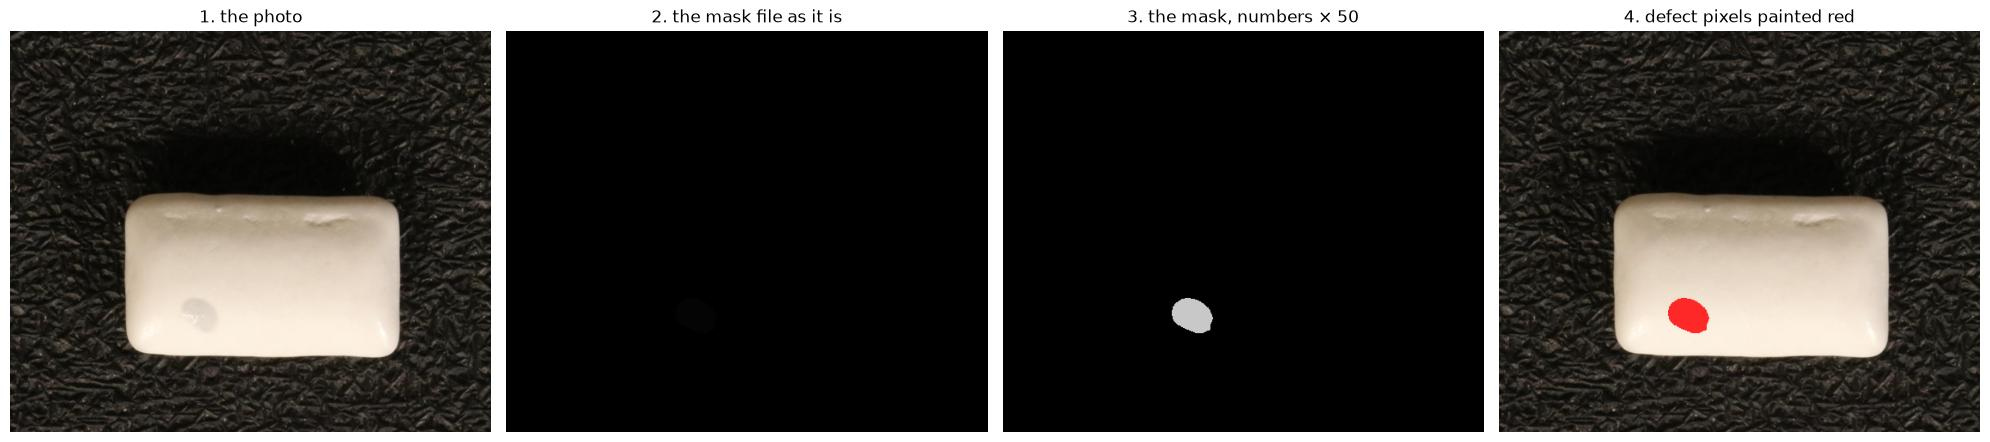

In [12]:
example = type_sizes[type_sizes["defect type"] == "similar colour spot"].nlargest(1, "size %").iloc[0]
photo = photos.loc[example["photo"]]

full_photo = Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB")
full_mask = Image.open(os.path.join(RAW_DIR, photo["mask"]))
mask_values = np.asarray(full_mask)
number_range = np.iinfo(mask_values.dtype)
print("Photo:", os.path.basename(photo["image"]), "| photo size:", full_photo.size, "| mask size:", full_mask.size)
print("Numbers in this mask:", np.unique(mask_values))
print(f"Number type of the mask: {mask_values.dtype} (whole numbers from {number_range.min} to {number_range.max})")

# make both smaller for showing (NEAREST keeps the mask numbers unchanged)
small_size = (SHOW_WIDTH, round(full_photo.height * SHOW_WIDTH / full_photo.width))
small_photo = np.asarray(full_photo.resize(small_size))
small_mask = np.asarray(full_mask.resize(small_size, Image.NEAREST))

overlay = small_photo.copy()
overlay[small_mask > 0] = [255, 40, 40]   # paint the defect pixels red

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
axes[0].imshow(small_photo)
axes[0].set_title("1. the photo")
axes[1].imshow(small_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("2. the mask file as it is")
axes[2].imshow(np.clip(small_mask.astype(int) * 50, 0, 255), cmap="gray", vmin=0, vmax=255)
axes[2].set_title("3. the mask, numbers × 50")
axes[3].imshow(overlay)
axes[3].set_title("4. defect pixels painted red")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Question 5: How Big Are the Defects?

### Defect Size

> Size = how much of the photo is defect, in percent. How to read the table:
>
> - `count`: number of defect photos; `mean`: the average size; `std`: how spread out the sizes are
> - `25%`, `50%`, `75%`: a quarter, half and three quarters of the photos have a smaller defect than this. `50%` is the median.

count    100.000
mean       0.847
std        0.785
min        0.033
25%        0.231
50%        0.533
75%        1.310
max        3.306

Defect photos where the defect covers less than 1% of the photo: 63 of 100


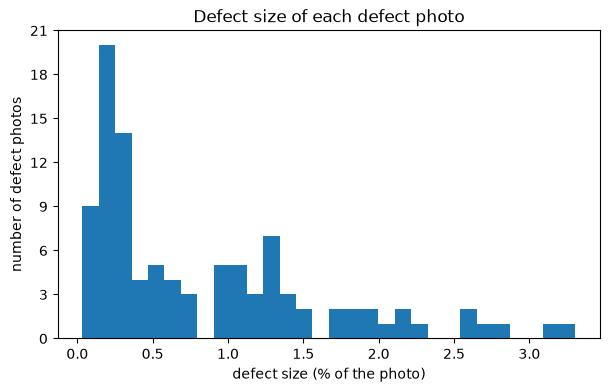

In [13]:
print(defects["size %"].describe().round(3).to_string())
print(f"\nDefect photos where the defect covers less than 1% of the photo: "
      f"{(defects['size %'] < 1).sum()} of {len(defects)}")

plt.figure(figsize=(7, 4))
plt.hist(defects["size %"], bins=30)
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))   # photo counts are whole numbers
plt.xlabel("defect size (% of the photo)")
plt.ylabel("number of defect photos")
plt.title("Defect size of each defect photo")
plt.show()

> **What we see:** the defects are tiny. The median (`50%`) is 0.533%: in half of the defect photos, all defects together cover less than about half a percent of the photo. 63 of the 100 cover less than 1%.
>
> If we shrink the photos too much before training, small defects can disappear. So the image size we choose will matter for both models.

### Size per Defect Type

> The same size, but for each defect type on its own. A photo with two types gives one size for each type. The last column gives the median in pixels (the number of pixels in one photo is printed in Load Data). The table is sorted from the smallest type to the biggest.

In [14]:
by_type = type_sizes.groupby("defect type")
size_table = pd.DataFrame({
    "photos": by_type.size(),
    "median size %": by_type["size %"].median(),
    "smallest size %": by_type["size %"].min(),
    "biggest size %": by_type["size %"].max(),
    "median pixels": by_type["pixels"].median().astype(int),
}).sort_values("median size %").round(4)
size_table

,photos,median size %,smallest size %,biggest size %,median pixels
defect type,,,,,
small cracks,29,0.0279,0.0001,0.1273,419
scratches,16,0.0483,0.0130,0.1950,724
corner missing,36,0.1728,0.0124,1.3306,2593
similar colour spot,25,0.2482,0.1283,0.5578,3724
chunk of gum missing,47,1.2736,0.3526,3.2464,19108


> **What we see:** *small cracks* and *scratches* are by far the smallest. Their median is under 0.05% of the photo: 419 and 724 pixels out of 1,500,356. *chunk of gum missing* is the biggest. We expect the thin types to be the hardest to catch, and we will check this in the evaluation step.
>
> The smallest *small cracks* value (0.0001%) is a crack of only 1 pixel. Question 7 looks at it.

## Question 6: Where in the Photo Are the Defects?

### Average Photo and Defect Map

> - **Left:** the average of all normal photos. If it looks sharp, the gum is in the same place in every photo.
> - **Right:** all defect masks added together. Brighter = more photos have a defect at that spot.
>
> To make this fast, every photo and mask is first made about 4 times smaller (`MAP_SIZE`). Each mask is first turned into black (0) and white (255), so even a tiny defect stays visible after shrinking.

Adding up the masks: 100%|██████████| 100/100 [00:00<00:00, 125.79it/s]


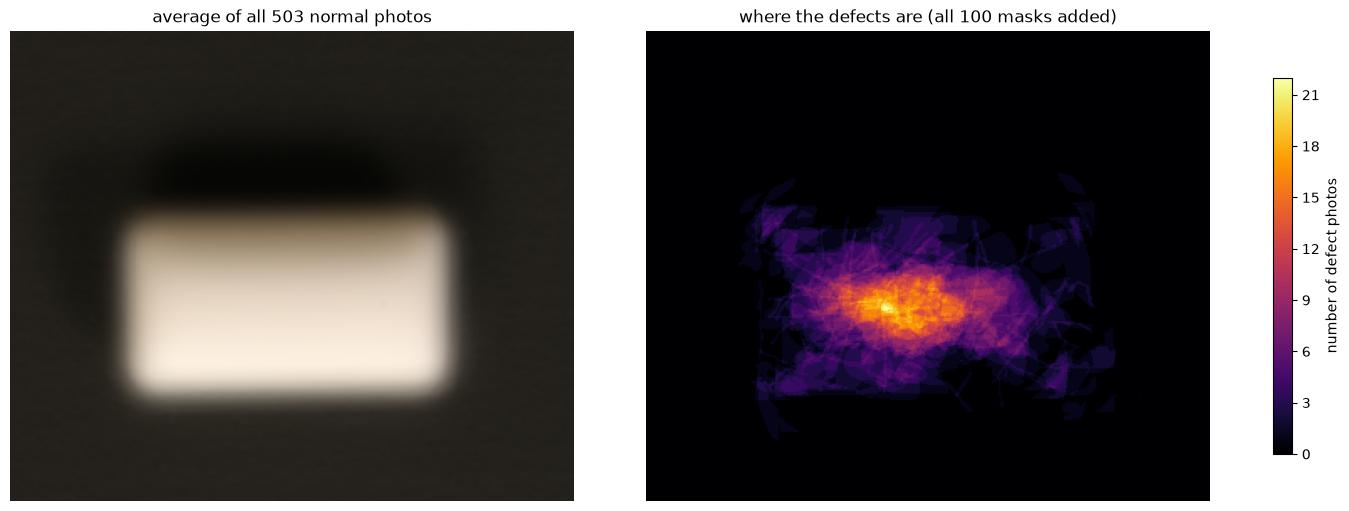

In [15]:
normal_paths = photos.loc[~photos["is_defect"], "image"]
average = np.zeros((MAP_SIZE[1], MAP_SIZE[0], 3))
for rel_path in tqdm(normal_paths, desc="Adding up the normal photos"):
    average += np.asarray(Image.open(os.path.join(RAW_DIR, rel_path)).convert("RGB").resize(MAP_SIZE))
average = (average / len(normal_paths)).astype(np.uint8)

defect_map = np.zeros((MAP_SIZE[1], MAP_SIZE[0]))
for rel_path in tqdm(defects["mask"], desc="Adding up the masks"):
    black_white = Image.fromarray(((open_mask(rel_path) > 0) * 255).astype(np.uint8))
    defect_map += np.asarray(black_white.resize(MAP_SIZE, Image.BOX)) > 0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
axes[0].imshow(average)
axes[0].set_title(f"average of all {len(normal_paths)} normal photos")
picture = axes[1].imshow(defect_map, cmap="inferno")
axes[1].set_title(f"where the defects are (all {len(defects)} masks added)")
fig.colorbar(picture, ax=axes, shrink=0.8, ticks=MaxNLocator(integer=True), label="number of defect photos")
for ax in axes:
    ax.axis("off")
plt.show()

> **What we see:** the average photo shows a blurry bar in the middle. So the gum is always near the centre, but its exact place moves a little between photos. The defects are spread over the whole gum. Most are in the middle of the gum, and some are on its edges and corners.

## Question 7: Is Every Defect One Clean Piece in Its Mask?

### Count the Pieces in Each Mask

> YOLO learns from boxes. The simplest way to make boxes from a mask is one box around each separate piece. A piece is a group of defect pixels that touch each other (also corner to corner, see `TOUCHING`).
>
> - `ndimage.label()` finds the pieces and gives each piece its own number.
> - `np.bincount()` counts the pixels of each piece.
>
> The table shows, per defect type, how many pieces there are and how big they are (in pixels).

In [16]:
rows = []
for i, photo in tqdm(defects.iterrows(), total=len(defects), desc="Counting the pieces in each mask"):
    mask = open_mask(photo["mask"])
    for number, name in MASK_CODE.items():
        pieces, n_pieces = ndimage.label(mask == number, structure=TOUCHING)
        for n_pixels in np.bincount(pieces.ravel())[1:]:   # [1:] skips 0, the pixels that are not this type
            rows.append({"photo": i, "defect type": name, "pixels": int(n_pixels)})
mask_pieces = pd.DataFrame(rows)

pieces_per_photo = mask_pieces.groupby("photo").size()
most = pieces_per_photo.idxmax()
print(f"Pieces in all masks: {len(mask_pieces)}")
print(f"Defect photos with more than one piece: {(pieces_per_photo > 1).sum()} of {len(defects)}")
print(f"Most pieces in one photo: {pieces_per_photo.max()} ({os.path.basename(photos.loc[most, 'image'])})")
print(f"Tiny pieces (fewer than 10 pixels): {(mask_pieces['pixels'] < 10).sum()}")

pieces_by_type = mask_pieces.groupby("defect type")
pd.DataFrame({
    "photos": pieces_by_type["photo"].nunique(),
    "pieces": pieces_by_type.size(),
    "smallest piece (pixels)": pieces_by_type["pixels"].min(),
    "median piece (pixels)": pieces_by_type["pixels"].median().astype(int),
})

Counting the pieces in each mask: 100%|██████████| 100/100 [00:06<00:00, 15.07it/s]

Pieces in all masks: 256
Defect photos with more than one piece: 58 of 100
Most pieces in one photo: 32 (068.JPG)
Tiny pieces (fewer than 10 pixels): 41


,photos,pieces,smallest piece (pixels),median piece (pixels)
defect type,,,,
chunk of gum missing,47,56,165,16705
corner missing,36,51,1,1228
scratches,16,63,1,7
similar colour spot,25,25,1925,3724
small cracks,29,61,1,245


### Look at the Photo with the Most Pieces

> A close-up of the photo with the most pieces. Left: the photo. Right: the defect pixels in red, with one yellow box around each piece. This is what "one box per piece" would give YOLO.

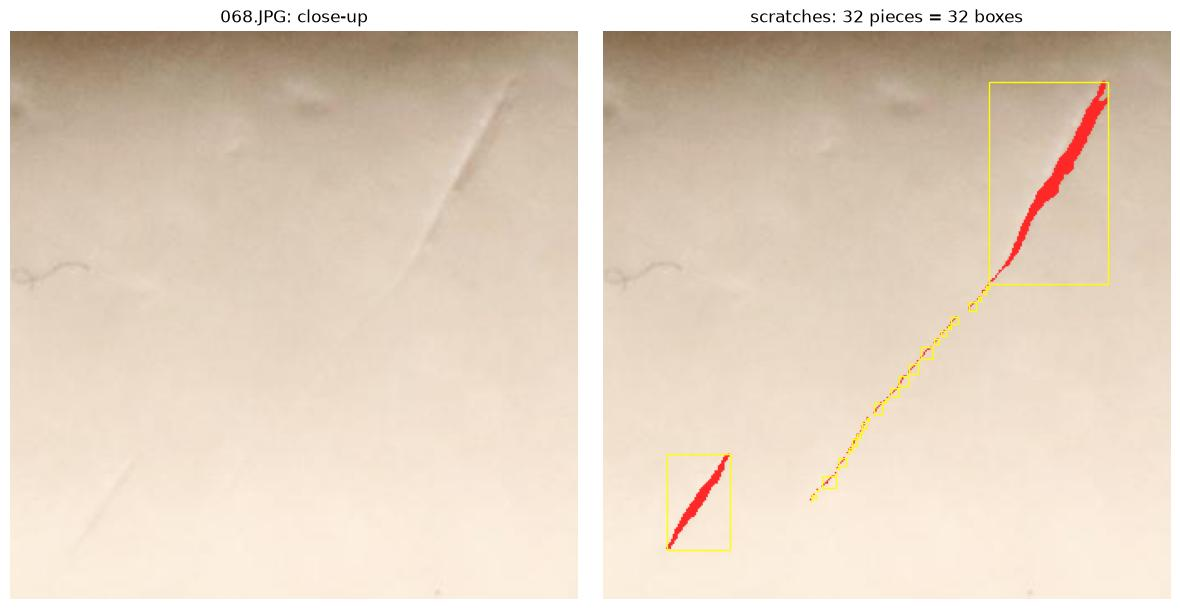

In [17]:
photo = photos.loc[most]
name = mask_pieces.loc[mask_pieces["photo"] == most, "defect type"].mode()[0]   # its main defect type
this_type = open_mask(photo["mask"]) == TYPE_CODE[name]
pieces, n_pieces = ndimage.label(this_type, structure=TOUCHING)

left, top, right, bottom = square_around(defect_box(this_type), this_type.shape[1], this_type.shape[0],
                                         margin=30, min_side=200)
close_up = np.asarray(Image.open(os.path.join(RAW_DIR, photo["image"])).convert("RGB"))[top:bottom, left:right]
painted = close_up.copy()
painted[this_type[top:bottom, left:right]] = [255, 40, 40]   # defect pixels in red

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(close_up)
axes[0].set_title(f"{os.path.basename(photo['image'])}: close-up")
axes[1].imshow(painted)
for row_slice, col_slice in ndimage.find_objects(pieces):   # one box per piece
    axes[1].add_patch(Rectangle((col_slice.start - left, row_slice.start - top),
                                col_slice.stop - col_slice.start, row_slice.stop - row_slice.start,
                                fill=False, edgecolor="yellow", linewidth=1))
axes[1].set_title(f"{name}: {n_pieces} pieces = {n_pieces} boxes")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Look at Defect Types with Almost No Pixels

> The photo list says which defect types each photo has. Here we look for a defect type that covers fewer than 10 pixels in a whole photo, and print the mask numbers around such a pixel.
>
> Remember the numbers: 1 = chunk of gum missing, 2 = corner missing, 3 = scratches, 4 = similar colour spot, 5 = small cracks.

In [18]:
almost_none = type_sizes[type_sizes["pixels"] < 10].copy()
almost_none["image"] = photos.loc[almost_none["photo"], "image"].values
print(almost_none[["image", "defect type", "pixels"]].to_string(index=False))

first = almost_none.iloc[0]
mask = open_mask(photos.loc[first["photo"], "mask"])
pixel_rows, pixel_cols = np.nonzero(mask == TYPE_CODE[first["defect type"]])
r, c = pixel_rows[0], pixel_cols[0]
print(f"\nMask numbers around that pixel (row {r}, column {c}):")
print(mask[r - 5:r + 6, c - 5:c + 6])

                                 image  defect type  pixels
chewinggum/Data/Images/Anomaly/057.JPG small cracks       1

Mask numbers around that pixel (row 557, column 688):
[[0 0 0 0 0 0 0 0 0 0 3]
 [0 0 0 0 0 0 0 0 3 3 3]
 [0 0 0 0 0 0 0 0 3 3 3]
 [0 0 0 0 0 0 0 3 3 3 3]
 [0 0 0 0 0 0 3 3 3 0 0]
 [0 0 0 0 0 5 3 3 3 0 0]
 [0 0 0 0 0 3 3 3 3 0 0]
 [0 0 0 0 0 1 3 3 3 1 0]
 [0 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1 1 1 1 1]]


> **What we see:** many masks are split into pieces, and some pieces are tiny.
>
> - In 068.JPG, one long scratch is drawn as a thin broken line, so it becomes 32 pieces. One box per piece would give YOLO 32 boxes, most of them only a few pixels, for what is really one or two scratches.
> - In 057.JPG, the photo list says *small cracks*, but the mask has only 1 crack pixel (the `5` in the printed numbers). It sits between `3` (scratches) and `1` (chunk of gum missing). Most likely the crack was covered by the other two labels.
>
> So in step 3 we will not simply make one box per piece. We will join pieces that are close together and drop pieces of only a few pixels.

## Summary

> **What we learned**
>
> - 503 normal and 100 defect photos (17% defect). 43 defect photos have more than one defect type. 6 normal photos show the same gum as another photo and are left out of the splits (notebook 1.2).
> - *scratches* is the rarest type (16 photos).
> - The defects are small: 63 of 100 cover less than 1% of the photo. *small cracks* and *scratches* are the smallest.
> - The gum is always near the middle of the photo, but its place moves a little.
> - The masks are not always clean: one scratch is split into 32 pieces, and one crack has only 1 pixel.
>
> **What this means for the next steps**
>
> - Keep enough detail when we resize the photos, or small defects disappear.
> - When we turn masks into YOLO boxes (step 3), join nearby pieces and drop pieces of only a few pixels.
> - PatchCore learns from normal photos only, so the mask problems do not change how it learns.
> - Report results per defect type, because the thin types will probably be the hardest.
>
> **Next step:** the notebooks in `notebooks/3_preprocessing/`